In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df=pd.read_csv("/content/1) iris.csv")

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [11]:
df.duplicated().sum()

np.int64(3)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [15]:
df = pd.read_csv('1) iris.csv')

In [16]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [17]:
target_col = 'Species' if 'Species' in df.columns else df.columns[-1]

In [18]:
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])
X = df.drop(columns=[target_col])
y = df[target_col]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training shape: {X_train.shape}")
print(f"Testing shape : {X_test.shape}")

Training shape: (120, 4)
Testing shape : (30, 4)


In [20]:
dt_unpruned = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_unpruned.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [21]:
train_acc = accuracy_score(y_train, dt_unpruned.predict(X_train))
test_acc = accuracy_score(y_test, dt_unpruned.predict(X_test))
print("--- Unpruned Model Performance ---")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy : {test_acc:.4f}")

--- Unpruned Model Performance ---
Training Accuracy: 1.0000
Testing Accuracy : 0.9333


In [22]:
dt_pruned = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)
dt_pruned.fit(X_train, y_train)
print("Pruned Decision Tree trained successfully.")

Pruned Decision Tree trained successfully.


In [23]:
y_pred = dt_pruned.predict(X_test)
print("--- Pruned Model Evaluation ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred, average='weighted'):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

--- Pruned Model Evaluation ---
Accuracy : 0.9667
Precision: 0.9697
Recall   : 0.9667
F1 Score : 0.9666

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



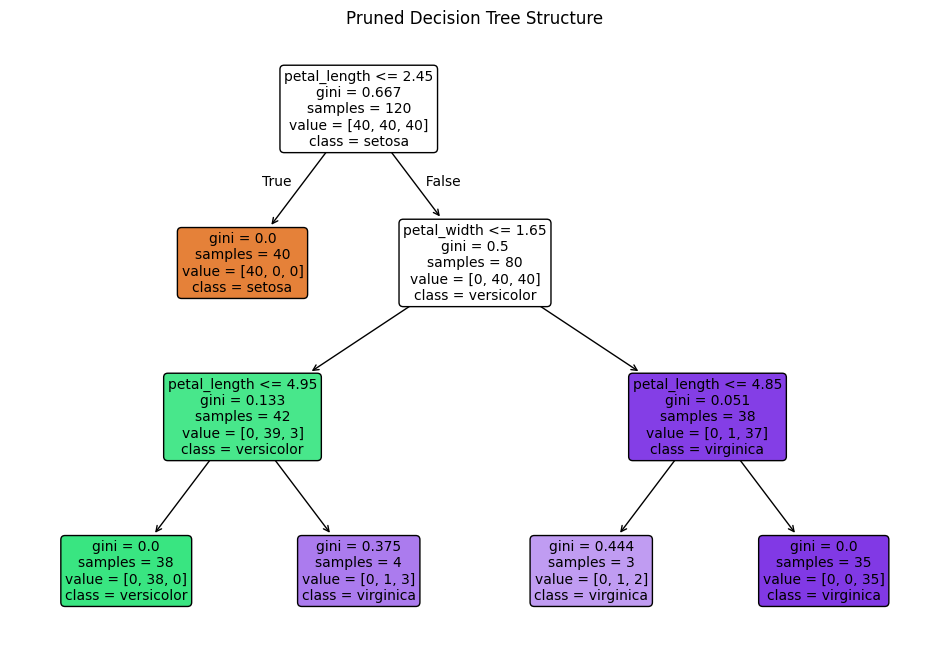

In [24]:
plt.figure(figsize=(12, 8))
plot_tree(
    dt_pruned,
    feature_names=X.columns,
    class_names=[str(c) for c in np.unique(y)],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Pruned Decision Tree Structure")
plt.show()

In [25]:
print("\n--- Text Rules ---")
print(export_text(dt_pruned, feature_names=list(X.columns)))


--- Text Rules ---
|--- petal_length <= 2.45
|   |--- class: setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.65
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.95
|   |   |   |--- class: virginica
|   |--- petal_width >  1.65
|   |   |--- petal_length <= 4.85
|   |   |   |--- class: virginica
|   |   |--- petal_length >  4.85
|   |   |   |--- class: virginica

